# EDA de imágenes (entrenamiento)

Este notebook usa solo las imágenes de entrenamiento de `data/splits.csv`. La única
excepción es la sección 8 (validación adversarial), que usa imágenes de test sin sus
etiquetas. Todos los parámetros se leen de `configs/base.yaml`.

## 1. Carga de la partición

Se carga la partición, se conservan las filas con `split == "train"` y se añaden los
metadatos de esas imágenes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from src import data, eda, stats
from src.utils import set_seed

2026-11-12 21:48:35.271068: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
cfg = data.load_config()
set_seed(cfg["seed"])
rutas = cfg["paths"]

In [3]:
splits = data.load_splits(rutas["splits_csv"])
meta = data.load_metadata(cfg)
train = (splits[splits["split"] == "train"]
         .merge(meta.drop(columns=["lesion_id", "dx"]), on="image_id", how="left")
         .reset_index(drop=True))

ids_test = set(splits.loc[splits["split"] == "test", "image_id"])
assert (train["split"] == "train").all(), "Hay filas que no son de entrenamiento"
assert ids_test.isdisjoint(train["image_id"]), "Hay imágenes de test en el conjunto de trabajo"
print(f"Imágenes de entrenamiento: {len(train)}")

Imágenes de entrenamiento: 8584


In [4]:
orden_dx = train["dx"].value_counts().index.tolist()
fuente = cfg["source_column"]
tiene_fuente = data.has_source_column(train, cfg)
rutas_orig = data.image_paths(cfg, train["image_id"])

## 2. Caché

Versiones reducidas de las imágenes de entrenamiento (lado mayor `eda_cache_max_side`,
relación de aspecto conservada) en `data/processed/eda_cache/`. Las que ya existen se
reutilizan.

In [5]:
cache = eda.build_cache(train["image_id"], rutas_orig, rutas["eda_cache_dir"],
                        cfg["eda_cache_max_side"], cfg["eda_cache_format"], cfg["eda_cache_jpeg_quality"])
train["cache_path"] = train["image_id"].map(cache)
print(f"Imágenes en caché: {train['cache_path'].notna().sum()}")

Caché EDA:   0%|          | 0/8584 [00:00<?, ?it/s]

Imágenes en caché: 8584


## 3. Inspección visual

`eda_grid_per_class` imágenes aleatorias por clase (semilla fija), con su `image_id` y `dx`.

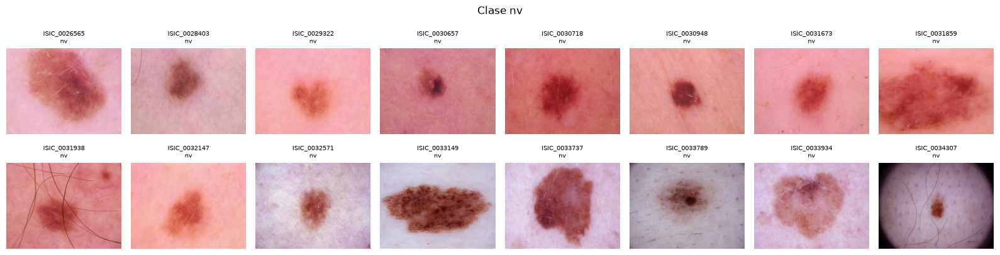

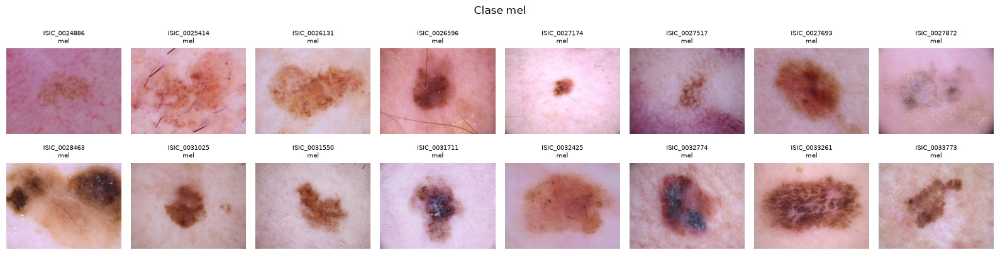

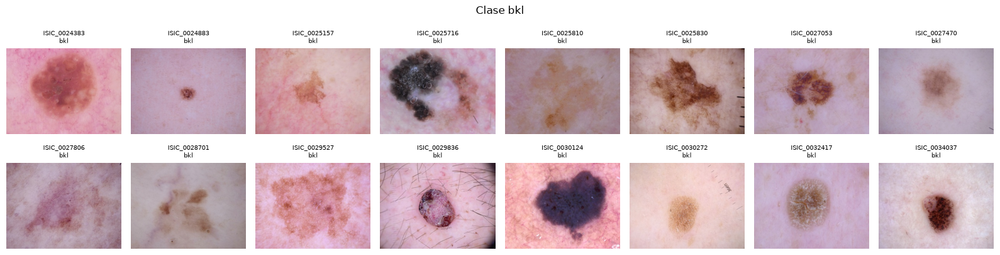

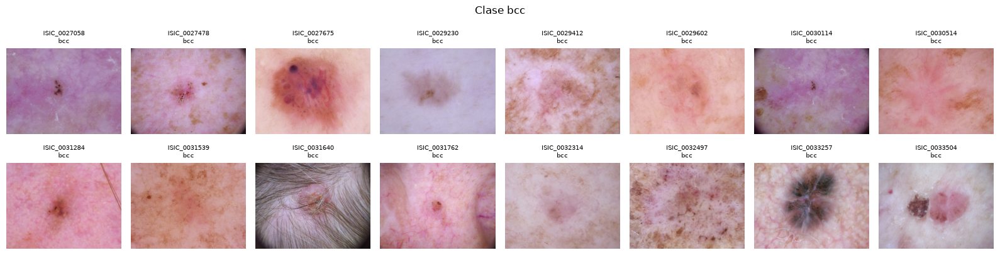

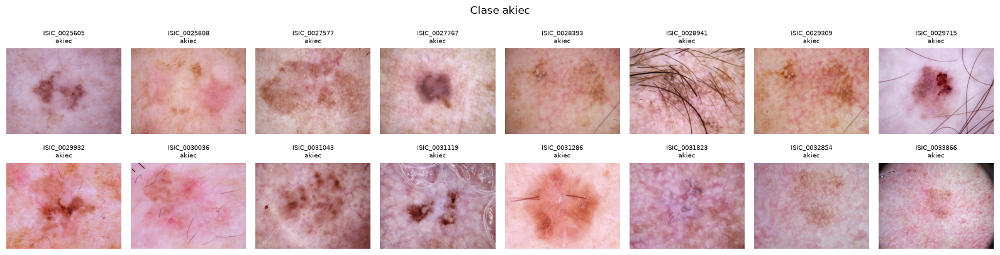

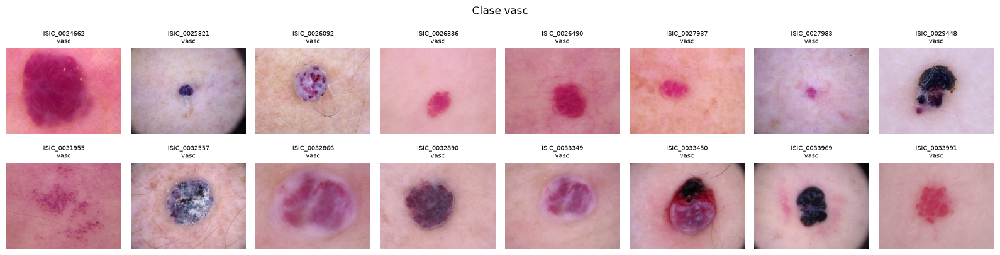

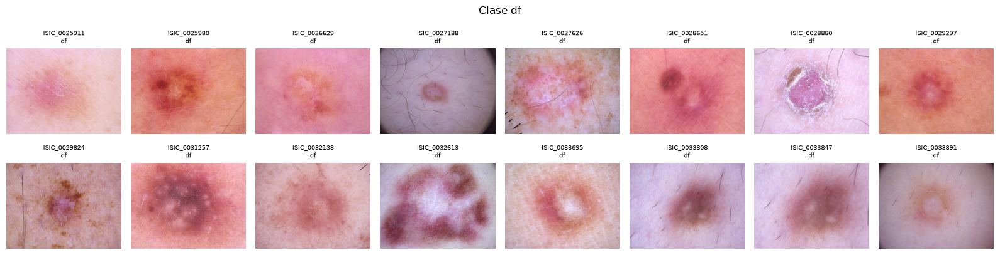

In [6]:
muestra = eda.sample_per_class(train, cfg["eda_grid_per_class"], cfg["seed"])
for dx in orden_dx:
    sub = muestra[muestra["dx"] == dx]
    eda.plot_image_grid(sub["cache_path"], sub["image_id"] + "\n" + sub["dx"],
                        ncols=cfg["eda_grid_ncols"], suptitle=f"Clase {dx}")
    plt.show()

## 4. Artefactos

### 4.1 Plantilla de anotación

Muestra estratificada de `eda_annotation_per_class` imágenes por clase (todas si hay
menos) en `data/anotacion_artefactos.csv`, con una columna vacía por artefacto. Si el
archivo ya existe, no se sobrescribe.

In [7]:
ruta_anot = rutas["artifacts_annotation_csv"]
cols_art = cfg["artifact_columns"]
if ruta_anot.exists():
    print(f"Se usa el archivo existente: {ruta_anot}")
else:
    muestra_anot = eda.sample_per_class(train, cfg["eda_annotation_per_class"], cfg["seed"])
    eda.annotation_template(muestra_anot, cols_art).to_csv(ruta_anot, index=False)
    print(f"Plantilla creada: {ruta_anot}")
anot = pd.read_csv(ruta_anot)
anot["dx"].value_counts().loc[orden_dx].rename("imágenes a anotar").to_frame()

Plantilla creada: /var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/data/anotacion_artefactos.csv


,imágenes a anotar
dx,
nv,40
mel,40
bkl,40
bcc,40
akiec,40
vasc,40
df,40


Imágenes de la plantilla por páginas de `eda_annotation_page_size`. El número antes de
cada `image_id` es la fila del CSV (empezando en 0). Cambia `pagina` para avanzar.

Página 1 de 14


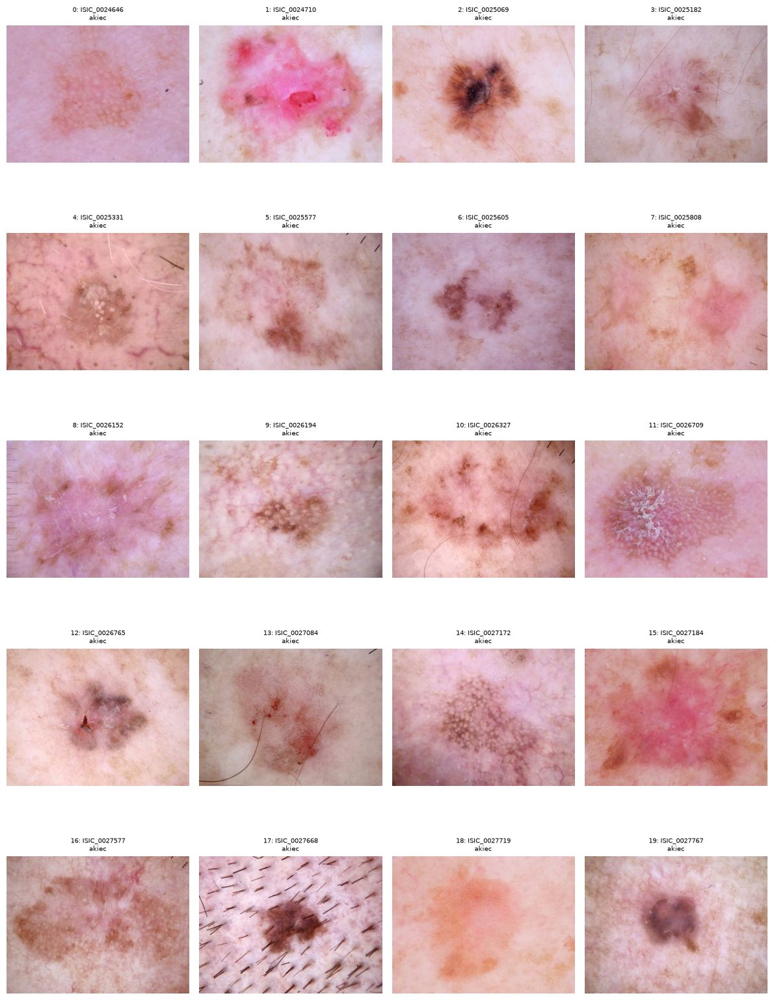

In [8]:
pagina = 0
tam = cfg["eda_annotation_page_size"]
n_paginas = int(np.ceil(len(anot) / tam))
sub = anot.iloc[pagina * tam:(pagina + 1) * tam]
print(f"Página {pagina + 1} de {n_paginas}")
eda.plot_image_grid(sub["image_id"].map(cache),
                    sub.index.to_series().astype(str) + ": " + sub["image_id"] + "\n" + sub["dx"],
                    ncols=cfg["eda_grid_ncols"] // 2, cell_size=3)
plt.show()

### 4.2 Prevalencia de artefactos por clase

Solo si todas las filas tienen las columnas de artefacto en 0 o 1. Chi-cuadrado y V de
Cramér de cada artefacto frente a `dx`.

In [9]:
estado = eda.annotation_status(anot, cols_art)
print(estado)
if estado["completo"]:
    display(eda.artifact_prevalence(anot, cols_art).loc[orden_dx].round(1))
    display(stats.chi2_table(anot.assign(**{c: pd.to_numeric(anot[c]) for c in cols_art}), cols_art, "dx"))
else:
    print(f"AVISO: {ruta_anot} no está anotado por completo "
          f"({estado['n_completas']} de {estado['n_filas']} filas). Se omite el análisis.")

{'n_filas': 280, 'n_completas': 0, 'n_celdas_no_validas': 0, 'completo': False}
AVISO: /var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/data/anotacion_artefactos.csv no está anotado por completo (0 de 280 filas). Se omite el análisis.


### 4.3 Indicador automático de viñeteado

Razón entre la intensidad media de las cuatro esquinas y la de una ventana central
(escala de grises, sobre la caché), por clase, con Kruskal-Wallis.

Viñeteado:   0%|          | 0/8584 [00:00<?, ?it/s]

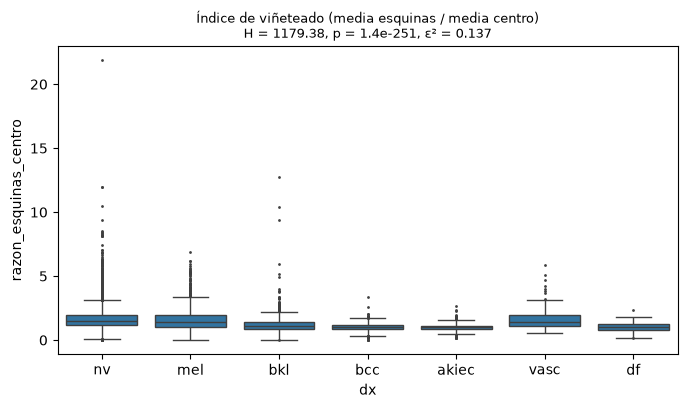

,count,mean,std,min,25%,50%,75%,max
dx,,,,,,,,
nv,5747.0,1.682268,0.918105,0.013502,1.202820,1.513666,1.973155,21.886592
mel,954.0,1.579892,1.052967,0.012917,0.992252,1.388866,1.956032,6.904810
bkl,942.0,1.183962,0.832471,0.001375,0.837063,1.099357,1.382499,12.736711
bcc,440.0,1.028559,0.359858,0.016764,0.856131,1.034776,1.207078,3.404327
akiec,281.0,1.008664,0.318522,0.124213,0.851625,1.014428,1.131325,2.687431
vasc,122.0,1.695630,0.917714,0.542890,1.117631,1.435847,1.925679,5.843449
df,98.0,1.028315,0.367736,0.151265,0.820647,1.059464,1.266637,2.359974


In [10]:
vin = eda.vignetting_table(train["image_id"], train["cache_path"],
                           cfg["eda_vignette_corner_frac"], cfg["eda_vignette_center_frac"])
vin = vin.merge(train[["image_id", "dx"]], on="image_id")
res_vin = stats.kruskal_epsilon2(vin["razon_esquinas_centro"], vin["dx"])
eda.boxplot_by_class(vin, "razon_esquinas_centro", "dx", order=orden_dx,
                     title="Índice de viñeteado (media esquinas / media centro)", test=res_vin)
plt.show()
vin.groupby("dx")["razon_esquinas_centro"].describe().loc[orden_dx]

## 5. Dimensiones y formato

Ancho, alto, relación de aspecto, modo de color y tamaño de archivo de las imágenes
originales, por clase.

In [11]:
info = eda.file_info_table(train["image_id"], rutas_orig).merge(train[["image_id", "dx"]], on="image_id")
info["resolucion"] = info["ancho"].astype(str) + "x" + info["alto"].astype(str)
info.head()

Dimensiones:   0%|          | 0/8584 [00:00<?, ?it/s]

,image_id,ancho,alto,relacion_aspecto,modo,formato,tamano_kb,dx,resolucion
0,ISIC_0027419,600,450,1.333333,RGB,JPEG,304.610352,bkl,600x450
1,ISIC_0025030,600,450,1.333333,RGB,JPEG,311.632812,bkl,600x450
2,ISIC_0026769,600,450,1.333333,RGB,JPEG,294.756836,bkl,600x450
3,ISIC_0025661,600,450,1.333333,RGB,JPEG,337.428711,bkl,600x450
4,ISIC_0031633,600,450,1.333333,RGB,JPEG,250.268555,bkl,600x450


In [12]:
pd.crosstab(info["dx"], info["resolucion"], margins=True, margins_name="Total")

resolucion,600x450,Total
dx,,
akiec,281,281
bcc,440,440
bkl,942,942
df,98,98
mel,954,954
nv,5747,5747
vasc,122,122
Total,8584,8584


In [13]:
pd.crosstab(info["dx"], [info["formato"], info["modo"]], margins=True, margins_name="Total")

formato,JPEG,Total
modo,RGB,
dx,,
akiec,281,281
bcc,440,440
bkl,942,942
df,98,98
mel,954,954
nv,5747,5747
vasc,122,122
Total,8584,8584


In [14]:
info.groupby("dx")[["ancho", "alto", "relacion_aspecto", "tamano_kb"]].agg(["min", "median", "max"]).loc[orden_dx]

ancho             alto             relacion_aspecto                      \
        min median  max  min median  max              min    median       max   
dx                                                                              
nv      600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
mel     600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
bkl     600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
bcc     600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
akiec   600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
vasc    600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
df      600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   

        tamano_kb                          
              min      median         max  
dx                                         
nv      83.332031  269.440430  418.776367  
mel    122.078125  288.088867  479.273438  
bkl    121.448242  274.718262  404.376953  
bcc    106.122070  253.080078  448.410156  
akiec  133.724609  256.722656  360.993164  
vasc   157.337891  271.240723  410.137695  
df     134.268555  291.726074  370.289062

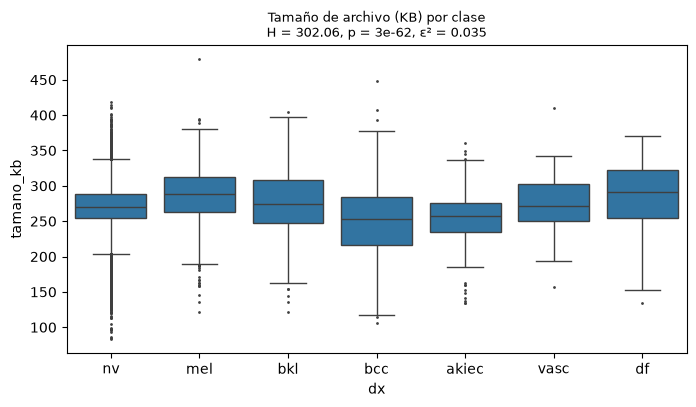

In [15]:
res_kb = stats.kruskal_epsilon2(info["tamano_kb"], info["dx"])
eda.boxplot_by_class(info, "tamano_kb", "dx", order=orden_dx, title="Tamaño de archivo (KB) por clase",
                     test=res_kb)
plt.show()

## 6. Color

### 6.1 Estadísticas globales por canal

Media y desviación estándar de R, G y B sobre todos los píxeles de las imágenes
originales de entrenamiento. Se guardan en `data/train_color_stats.json`. En la misma
pasada se calculan las características por imagen de 6.2.

In [16]:
color_img, color_global = eda.color_features(train["image_id"], rutas_orig, cfg["eda_luma_weights"])
data.save_json(color_global, rutas["train_color_stats_json"])
color_global

Color:   0%|          | 0/8584 [00:00<?, ?it/s]

{'escala': '[0, 1]',
 'canales': ['R', 'G', 'B'],
 'media': [0.7633448709457645, 0.5459043764893733, 0.5702200201908665],
 'std': [0.14142908930950454, 0.15309897687857643, 0.17048982974291169],
 'media_255': [194.65294209116996, 139.2056160047902, 145.40610514867095],
 'std_255': [36.06441777392366, 39.04023910403699, 43.47490658444248],
 'n_imagenes': 8584,
 'n_pixeles': 2317680000}

### 6.2 Color por imagen

Media de cada canal, luminancia, contraste (desviación de la luminancia) y saturación
(canal S de HSV), por clase, con Kruskal-Wallis y ε².

In [17]:
vars_color = ["media_r", "media_g", "media_b", "luminancia", "contraste", "saturacion"]
cols_extra = [fuente] if tiene_fuente else []
color = color_img.merge(train[["image_id", "dx", *cols_extra]], on="image_id")
kw_color = stats.kruskal_table(color, vars_color, "dx")
kw_color

,H,gl,p,epsilon2,n,k
media_r,1073.373719,6.0,1.201957e-228,0.125058,8584.0,7.0
media_g,430.220410,6.0,8.854310e-90,0.050125,8584.0,7.0
media_b,430.175077,6.0,9.055399e-90,0.050119,8584.0,7.0
luminancia,412.722729,6.0,5.138470e-86,0.048086,8584.0,7.0
contraste,579.866316,6.0,5.130870e-122,0.067560,8584.0,7.0
saturacion,984.746145,6.0,1.779977e-209,0.114732,8584.0,7.0


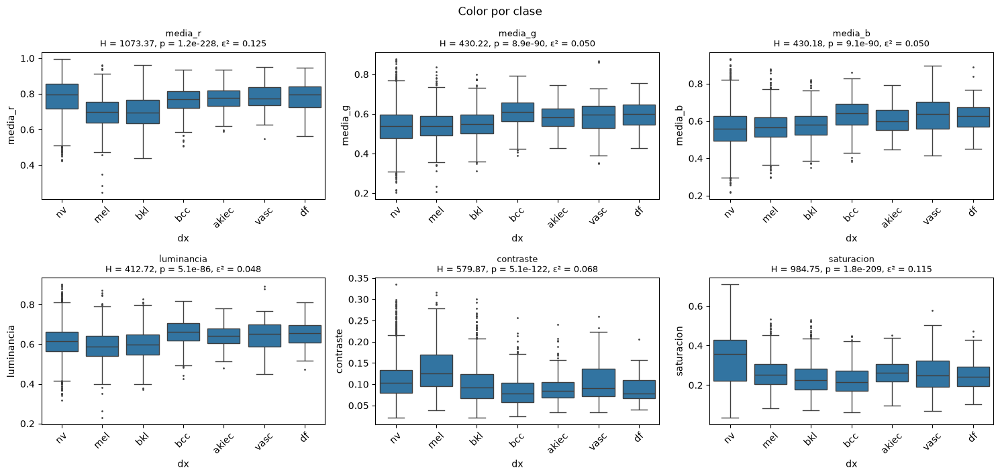

In [18]:
eda.boxplot_grid(color, vars_color, "dx", order=orden_dx, tests=kw_color, suptitle="Color por clase")
plt.show()

Las mismas variables por fuente, si existe la columna `source_column`.

,H,gl,p,epsilon2,n,k
media_r,3609.267243,3.0,0.000000e+00,0.420513,8584.0,4.0
media_g,1465.776912,3.0,0.000000e+00,0.170777,8584.0,4.0
media_b,1648.304158,3.0,0.000000e+00,0.192043,8584.0,4.0
luminancia,265.835954,3.0,2.456561e-57,0.030972,8584.0,4.0
contraste,685.965286,3.0,2.318749e-148,0.079921,8584.0,4.0
saturacion,5740.249998,3.0,0.000000e+00,0.668793,8584.0,4.0


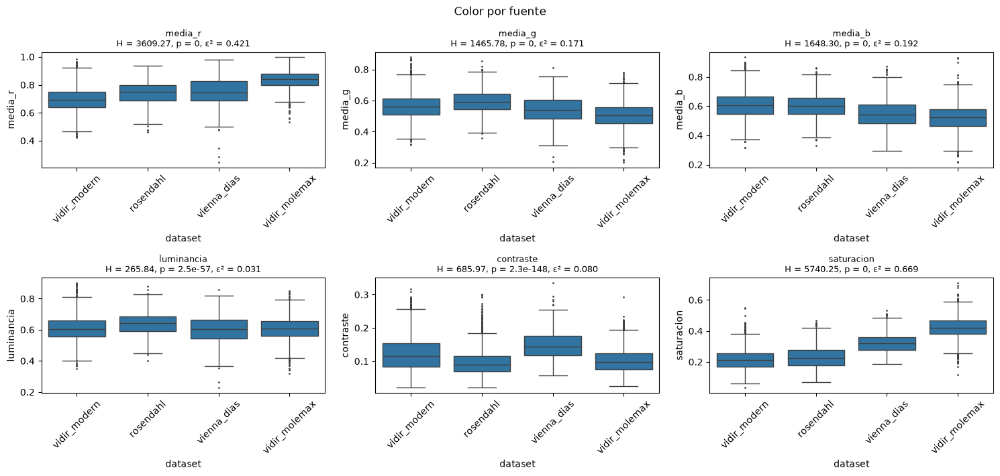

In [19]:
if tiene_fuente:
    kw_fuente = stats.kruskal_table(color, vars_color, fuente)
    display(kw_fuente)
    eda.boxplot_grid(color, vars_color, fuente, tests=kw_fuente, suptitle="Color por fuente")
    plt.show()
else:
    print(f"No existe la columna '{fuente}'.")

### 6.3 Shades of Gray

Constancia de color Shades of Gray con p = `shades_of_gray_p` aplicada a
`eda_sog_examples_per_class` imágenes por clase. Solo visualización: no se modifica
ningún archivo.

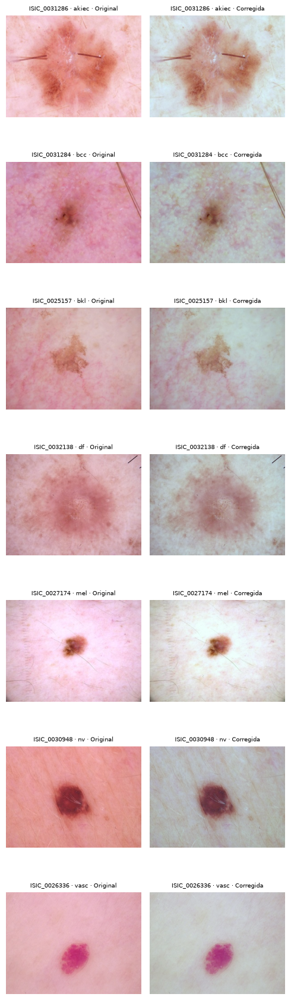

In [20]:
ejemplos = eda.sample_per_class(train, cfg["eda_sog_examples_per_class"], cfg["seed"])
eda.plot_before_after(ejemplos["cache_path"],
                      lambda im: eda.shades_of_gray(im, cfg["shades_of_gray_p"]),
                      ejemplos["image_id"] + " · " + ejemplos["dx"])
plt.show()

## 7. Tamaño y posición de la lesión

Con las máscaras de segmentación: fracción del área de la imagen ocupada por la lesión,
distancia del centroide al centro (normalizada por la semidiagonal) y si la lesión toca
el borde. Kruskal-Wallis para las dos variables continuas y chi-cuadrado con V de
Cramér para la variable binaria.

In [21]:
les = eda.lesion_features_table(train["image_id"], rutas_orig, data.mask_paths(cfg, train["image_id"]),
                                cfg["mask_threshold"], cfg["eda_luma_weights"])
les = les.merge(train[["image_id", "dx"]], on="image_id")
print(f"Imágenes sin máscara: {(~les['mascara_existe']).sum()}")

Máscaras:   0%|          | 0/8584 [00:00<?, ?it/s]

Imágenes sin máscara: 0


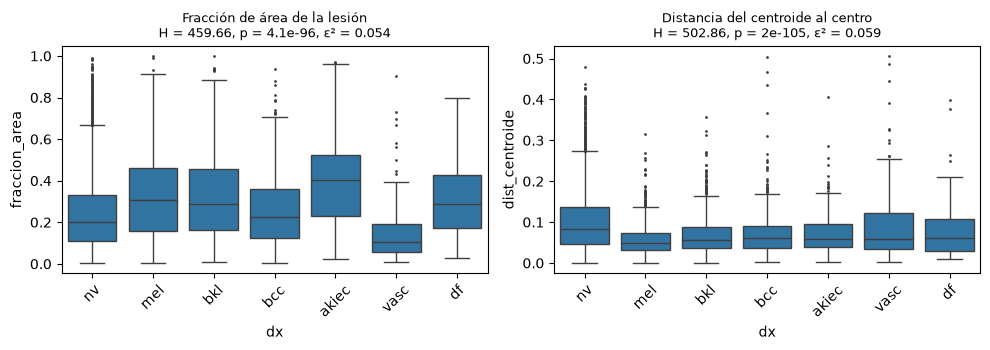

,H,gl,p,epsilon2,n,k
fraccion_area,459.659128,6.0,4.091189e-96,0.053555,8584.0,7.0
dist_centroide,502.861608,6.0,2.033531e-105,0.058588,8584.0,7.0


In [22]:
vars_les = ["fraccion_area", "dist_centroide"]
kw_les = stats.kruskal_table(les, vars_les, "dx")
eda.boxplot_grid(les, vars_les, "dx", order=orden_dx, tests=kw_les, ncols=2,
                 titles={"fraccion_area": "Fracción de área de la lesión",
                         "dist_centroide": "Distancia del centroide al centro"})
plt.show()
kw_les

In [23]:
toca = les.dropna(subset=["toca_borde"]).astype({"toca_borde": bool})
display((toca.groupby("dx")["toca_borde"].mean() * 100).loc[orden_dx].rename("% toca el borde").to_frame())
pd.Series(stats.chi2_from_columns(toca, "toca_borde", "dx"), name="toca_borde").to_frame()

,% toca el borde
dx,
nv,14.233513
mel,19.496855
bkl,20.063694
bcc,11.818182
akiec,34.519573
vasc,5.737705
df,14.285714


,toca_borde
chi2,1.214589e+02
gl,6.000000e+00
p,8.046258e-24
v_cramer,1.189515e-01
n,8.584000e+03
prop_esperadas_lt5,0.000000e+00


Color medio (RGB en [0, 1] y luminancia) dentro de la lesión y en el fondo, por clase, y
diferencia de luminancia lesión − fondo.

In [24]:
cols_rgb = [f"{r}_{c}" for r in ("lesion", "fondo") for c in ("r", "g", "b", "luminancia")]
les.groupby("dx")[cols_rgb].mean().loc[orden_dx].round(3)

,lesion_r,lesion_g,lesion_b,lesion_luminancia,fondo_r,fondo_g,fondo_b,fondo_luminancia
dx,,,,,,,,
nv,0.670,0.360,0.355,0.452,0.819,0.595,0.626,0.666
mel,0.605,0.390,0.388,0.454,0.741,0.610,0.649,0.654
bkl,0.655,0.463,0.467,0.521,0.719,0.583,0.624,0.628
bcc,0.743,0.541,0.575,0.605,0.771,0.631,0.654,0.675
akiec,0.762,0.534,0.550,0.604,0.781,0.613,0.636,0.665
vasc,0.639,0.330,0.461,0.438,0.811,0.627,0.668,0.687
df,0.761,0.516,0.547,0.593,0.796,0.636,0.667,0.687


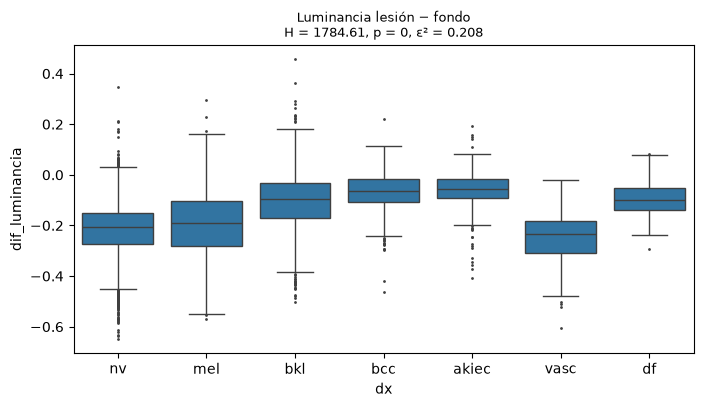

In [25]:
les["dif_luminancia"] = les["lesion_luminancia"] - les["fondo_luminancia"]
res_dif = stats.kruskal_epsilon2(les["dif_luminancia"], les["dx"])
eda.boxplot_by_class(les, "dif_luminancia", "dx", order=orden_dx,
                     title="Luminancia lesión − fondo", test=res_dif)
plt.show()

## 8. Desplazamiento de covariables (validación adversarial)

Histogramas de color de `adv_hist_bins` intervalos por canal para las imágenes de train y
de test de `splits.csv`. De test solo se usa el `image_id`, no las etiquetas. Una
regresión logística con validación cruzada estratificada de `adv_cv_folds` pliegues
predice si cada imagen es de test; se reporta el AUC medio y su desviación estándar.

In [26]:
ids_test_lista = splits.loc[splits["split"] == "test", "image_id"].tolist()
ids_adv = train["image_id"].tolist() + ids_test_lista
y_adv = np.r_[np.zeros(len(train), dtype=int), np.ones(len(ids_test_lista), dtype=int)]
X_adv = eda.color_histograms(data.image_paths(cfg, ids_adv), cfg["adv_hist_bins"])
print(X_adv.shape, np.bincount(y_adv))

Histogramas:   0%|          | 0/10015 [00:00<?, ?it/s]

(10015, 48) [8584 1431]


In [27]:
res_adv = eda.adversarial_validation(X_adv, y_adv, cfg["adv_cv_folds"], cfg["seed"], cfg["adv_max_iter"])
res_adv

{'auc_media': 0.4830792432515517,
 'auc_std': 0.012823288919265676,
 'auc_por_pliegue': [0.4925528751970219,
  0.4759582293070936,
  0.4610761981175493,
  0.49440803808887673,
  0.491400875547217]}

## 9. Embeddings

Solo si `eda_embeddings` es `true`. Características de MobileNetV2 preentrenada en
ImageNet (`keras.applications`, con su `preprocess_input`) sobre la caché de
entrenamiento, proyectadas a 2D con t-SNE y coloreadas por `dx` y por fuente. La primera
ejecución descarga los pesos de Keras.

In [28]:
proy = None
if cfg["eda_embeddings"]:
    emb = eda.mobilenet_embeddings(train["cache_path"], cfg["eda_embeddings_input_size"],
                                   cfg["eda_embeddings_batch_size"])
    xy = eda.tsne_2d(emb, cfg["seed"], cfg["eda_tsne_perplexity"])
    proy = train[["image_id", "dx", *([fuente] if tiene_fuente else [])]].assign(tsne_1=xy[:, 0], tsne_2=xy[:, 1])
else:
    print("eda_embeddings es false: se omite esta sección.")

eda_embeddings es false: se omite esta sección.


In [29]:
if proy is not None:
    colores = ["dx"] + ([fuente] if tiene_fuente else [])
    fig, axes = plt.subplots(1, len(colores), figsize=(7 * len(colores), 6), squeeze=False)
    for ax, col in zip(axes.ravel(), colores):
        sns.scatterplot(data=proy, x="tsne_1", y="tsne_2", hue=col, s=6, linewidth=0, ax=ax)
        ax.set_title(f"t-SNE de embeddings de MobileNetV2, coloreado por {col}")
    fig.tight_layout()
    plt.show()